<div style="background: linear-gradient(135deg,#1a3c64,#0d7377);
            padding:30px; border-radius:15px; text-align:center; color:white;">
             <h1>Projet : Detection masked face </h1>
  <h1>Approche 1 : Classificateur couleur → Fine-tuning YOLOv8-cls (images et vidéos)</h1>

  

 <div style="text-align:center;">
<h3 style="color:white; font-family:'Trebuchet MS', sans-serif;">

---

**Réalisé par :** Ihsane Foudal - Hiba Gourri - Hajar Bellafrouh

**Encadré par:** Mr. Yazid Safiny

--IID2--


</h3>
</div>
</div>



---

## Description

Ce notebook implémente un système complet de **détection de port du masque** en utilisant **YOLOv8**, un modèle de détection d'objets de pointe. Le projet est structuré en deux grandes parties :

1. **Approche initiale (Baseline)** : YOLOv8n pré-entraîné pour détecter les personnes + un classificateur heuristique basé sur la couleur pour distinguer masque / pas de masque.
2. **Amélioration (Fine-tuning)** : Fine-tuning de YOLOv8-cls directement sur notre dataset pour obtenir de meilleures performances.

---

## Structure des datasets attendue
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">
dataset/                        ← Dataset 1 : crops de visages
    Masked/                     ← visages masqués uniquement (recadrés)
    NonMasked/                  ← visages non masqués uniquement (recadrés)

dataset_image/                  ← Dataset 2 : images complètes
    with_mask/                  ← images complètes avec visages masqués
    without_mask/               ← images complètes sans masque


---

## Pipeline général

Image / Vidéo / Webcam
        │
        ▼
  YOLOv8n (détection personnes)
        │
        ▼
  Crop du visage (40% haut de la boîte)
        │
        ▼
  Classificateur mask / no_mask
  ├── Approche 1 : Heuristique couleur HSV
  └── Approche 2 : YOLOv8-cls fine-tuné (meilleure)
        │
        ▼
  Annotation + Métriques (Accuracy, Precision, Recall, F1)


---

## Bibliothèques requises

pip install ultralytics opencv-python torch torchvision
pip install matplotlib seaborn scikit-learn pillow tqdm



---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 0 — Vérification de l'environnement</u>
</h1>
</div>

Avant de commencer, on vérifie que toutes les bibliothèques nécessaires sont bien installées et on affiche leurs versions. On vérifie aussi si un GPU (CUDA) est disponible, ce qui accélérerait considérablement l'entraînement et l'inférence.



In [ ]:

print(' Bibliothèques déjà installées — vérifions les versions')
import ultralytics; print(f'Ultralytics: {ultralytics.__version__}')
import cv2; print(f'OpenCV: {cv2.__version__}')
import torch; print(f'PyTorch: {torch.__version__}')
print(f'GPU disponible: {torch.cuda.is_available()}')

✅ Bibliothèques déjà installées — vérifions les versions
Ultralytics: 8.4.37
OpenCV: 4.13.0
PyTorch: 2.11.0+cpu
GPU disponible: False


---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 1 — Imports et configuration globale</u>
</h1>
</div>

On importe toutes les bibliothèques nécessaires au projet :

- **`os`, `pathlib`** : gestion des fichiers et répertoires
- **`cv2` (OpenCV)** : traitement d'images et vidéo
- **`numpy`** : calculs numériques
- **`matplotlib`, `seaborn`** : visualisations et graphiques
- **`PIL` (Pillow)** : lecture/écriture d'images
- **`tqdm`** : barres de progression
- **`ultralytics`** : framework YOLOv8
- **`sklearn`** : métriques d'évaluation (accuracy, precision, recall, F1, matrice de confusion)

On configure également le **thème sombre** pour tous les graphiques matplotlib, et on définit la palette de couleurs du projet.


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from pathlib import Path
from tqdm import tqdm
from ultralytics import YOLO
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import warnings
warnings.filterwarnings('ignore')

# ─── Style matplotlib ───────────────────────────────────────────
plt.rcParams['figure.facecolor'] = '#0f0f1a'
plt.rcParams['axes.facecolor']   = '#1a1a2e'
plt.rcParams['text.color']       = 'white'
plt.rcParams['axes.labelcolor']  = 'white'
plt.rcParams['xtick.color']      = 'white'
plt.rcParams['ytick.color']      = 'white'
plt.rcParams['axes.edgecolor']   = '#444'
plt.rcParams['font.size']        = 12

COLORS = {'mask': '#00e5ff', 'no_mask': '#ff4081', 'neutral': '#b388ff'}
print('✅ Imports OK')

✅ Imports OK


---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 2 — Configuration des chemins et dossiers</u>
</h1>
</div>

On définit ici tous les chemins vers les datasets et le dossier de sortie pour les résultats.


La cellule vérifie ensuite automatiquement l'existence de chaque dossier et affiche le nombre d'images trouvées dans chacun. Les dossiers de sortie (`resultats/` et `resultats/images_annotees/`) sont créés automatiquement s'ils n'existent pas.


In [3]:
# ══════════════════════════════════════════════════════════════
#  MODIFIER CES CHEMINS SELON VOTRE MACHINE
# ══════════════════════════════════════════════════════════════

# Dataset 1 : crops de visages uniquement
DS1_MASKED    = r'dataset/Masked'
DS1_NONMASKED = r'dataset/NonMasked'

# Dataset 2 : images complètes (visage + contexte)
DS2_WITH      = r'dataset_image/with_mask'
DS2_WITHOUT   = r'dataset_image/without_mask'

# Résultats
OUTPUT_DIR = Path('resultats')
OUTPUT_DIR.mkdir(exist_ok=True)
(OUTPUT_DIR / 'images_annotees').mkdir(exist_ok=True)

# ─── Vérification ───────────────────────────────────────────────
paths = {
    'DS1 Masked'   : DS1_MASKED,
    'DS1 NonMasked': DS1_NONMASKED,
    'DS2 with_mask': DS2_WITH,
    'DS2 without'  : DS2_WITHOUT,
}

print('Vérification des chemins :')
for name, p in paths.items():
    exists = os.path.isdir(p)
    count  = len([f for f in os.listdir(p) if f.lower().endswith(('.jpg','.jpeg','.png','.bmp'))]) if exists else 0
    status = '✅' if exists else '❌'
    print(f'  {status} {name:20s} → {p}  ({count} images)')

Vérification des chemins :
  ✅ DS1 Masked           → dataset/Masked  (15442 images)
  ✅ DS1 NonMasked        → dataset/NonMasked  (15409 images)
  ✅ DS2 with_mask        → dataset_image/with_mask  (2162 images)
  ✅ DS2 without          → dataset_image/without_mask  (1930 images)


---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 3 — Exploration et statistiques des datasets</u>
</h1>
</div>

Avant de lancer le modèle, on analyse la composition de nos données :

- **Nombre d'images** par classe et par dataset
- **Distribution des classes** (équilibrée ou déséquilibrée ?)
- **Visualisation graphique** de la répartition

Un dataset bien équilibré (autant d'images masquées que non-masquées) est important pour éviter que le modèle ne soit biaisé vers une classe.


╔══════════════════════════════════════════╗
║        STATISTIQUES DES DATASETS         ║
╠══════════════════════════════════════════╣
║  Dataset 1 — Masked            : 15442 images ║
║  Dataset 1 — NonMasked         : 15409 images ║
║  Dataset 2 — with_mask         :  2164 images ║
║  Dataset 2 — without_mask      :  1930 images ║
╠══════════════════════════════════════════╣
║  Total Dataset 1                : 30851 images ║
║  Total Dataset 2                :  4094 images ║
║  TOTAL GÉNÉRAL                  : 34945 images ║
╚══════════════════════════════════════════╝


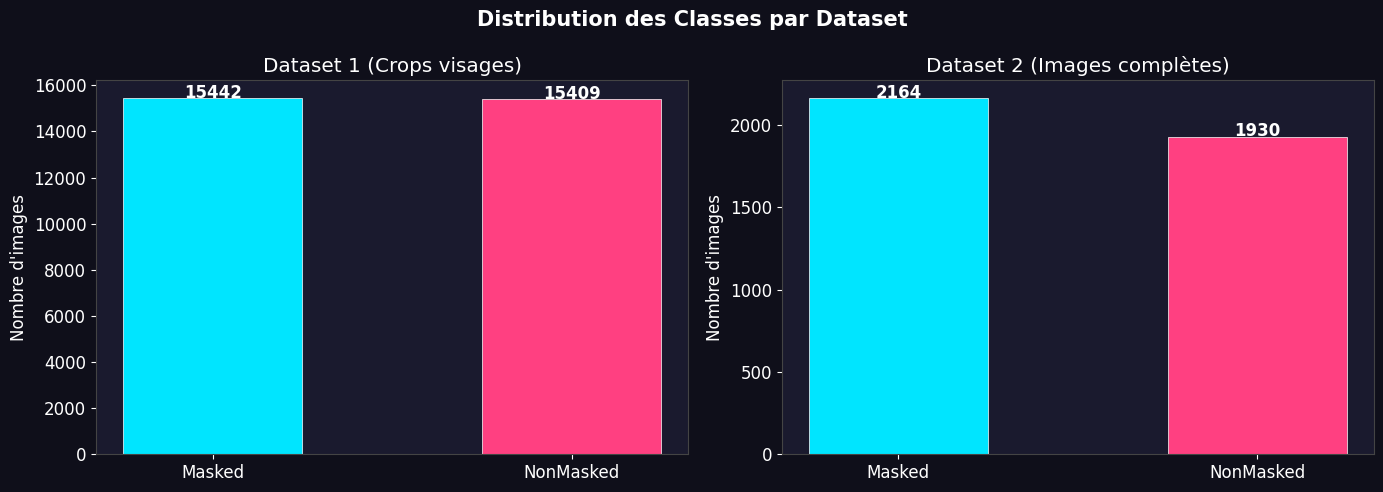

Graphique sauvegardé


In [4]:
def count_images(folder):
    exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
    if not os.path.isdir(folder):
        return 0
    return len([f for f in os.listdir(folder) if f.lower().endswith(exts)])

stats = {
    'Dataset 1 — Masked'      : count_images(DS1_MASKED),
    'Dataset 1 — NonMasked'   : count_images(DS1_NONMASKED),
    'Dataset 2 — with_mask'   : count_images(DS2_WITH),
    'Dataset 2 — without_mask': count_images(DS2_WITHOUT),
}

total_ds1 = stats['Dataset 1 — Masked'] + stats['Dataset 1 — NonMasked']
total_ds2 = stats['Dataset 2 — with_mask'] + stats['Dataset 2 — without_mask']

print('╔══════════════════════════════════════════╗')
print('║        STATISTIQUES DES DATASETS         ║')
print('╠══════════════════════════════════════════╣')
for k, v in stats.items():
    print(f'║  {k:30s}: {v:5d} images ║')
print('╠══════════════════════════════════════════╣')
print(f'║  Total Dataset 1                : {total_ds1:5d} images ║')
print(f'║  Total Dataset 2                : {total_ds2:5d} images ║')
print(f'║  TOTAL GÉNÉRAL                  : {total_ds1+total_ds2:5d} images ║')
print('╚══════════════════════════════════════════╝')

# ─── Graphique Distribution ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribution des Classes par Dataset', color='white', fontsize=15, fontweight='bold')

for ax, (title, m, nm) in zip(axes, [
    ('Dataset 1 (Crops visages)', stats['Dataset 1 — Masked'], stats['Dataset 1 — NonMasked']),
    ('Dataset 2 (Images complètes)', stats['Dataset 2 — with_mask'], stats['Dataset 2 — without_mask']),
]):
    bars = ax.bar(['Masked', 'NonMasked'], [m, nm],
                  color=[COLORS['mask'], COLORS['no_mask']], width=0.5,
                  edgecolor='white', linewidth=0.5)
    for bar, val in zip(bars, [m, nm]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(val), ha='center', color='white', fontweight='bold')
    ax.set_title(title, color='white')
    ax.set_ylabel('Nombre d\'images')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'distribution_dataset.png', dpi=150, bbox_inches='tight')
plt.show()
print('Graphique sauvegardé')

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 4 — Chargement du modèle YOLOv8</u>
</h1>
</div>

On charge ici le modèle **YOLOv8n** (version nano, la plus légère et rapide de la famille YOLOv8). Ce modèle a été pré-entraîné sur le dataset **COCO** qui contient 80 classes, dont la classe `person` (classe 0).

**Stratégie adoptée :**
- YOLOv8n est utilisé pour **détecter les personnes** dans l'image (boîte englobante complète)
- On extrait ensuite la **zone du visage** (40% haut de la boîte)
- Un classificateur séparé détermine si la personne porte un masque ou non



In [5]:
# Chargement YOLOv8 — modèle pré-entraîné sur COCO (détecte 'person' par défaut)
# Pour mask/no-mask : on utilise un modèle fine-tuné ou on adapte

print('Chargement du modèle YOLOv8...')

# Option A : modèle standard YOLOv8n (léger, rapide)
model = YOLO('yolov8n.pt')   # téléchargement automatique si absent

# Option B : si vous avez un modèle fine-tuné mask/no-mask
# model = YOLO('path/to/best.pt')

print(f'Modèle chargé : YOLOv8n')
print(f'Classes disponibles : {list(model.names.values())[:10]}...')
print(f'Pour mask/no-mask : le modèle détecte les personnes puis on classifie')

Chargement du modèle YOLOv8...
Modèle chargé : YOLOv8n
Classes disponibles : ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light']...
Pour mask/no-mask : le modèle détecte les personnes puis on classifie


---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 5 — Classificateur Mask / No-Mask et fonctions de détection</u>
</h1>
</div>

### Approche hybride (Baseline)

On définit ici deux fonctions principales :

#### 1. `classifier_mask_simple(face_crop)`
Un classificateur basé sur l'**analyse des couleurs HSV** dans la zone basse du visage (nez/bouche) :
- Détecte les teintes **blanc, bleu et gris** caractéristiques des masques chirurgicaux classiques
- Si le ratio de pixels "masque-like" dépasse 25% → prédit `mask`
- Sinon → prédit `no_mask`

> **Limitation connue** : cette approche ne fonctionne pas pour les masques de couleur noire, rouge ou à motifs. Elle est utilisée comme baseline pour montrer ses limites, avant d'introduire le fine-tuning.

#### 2. `detect_and_classify(image_path, conf_thresh)`
Pipeline complet :
1. Lit l'image avec OpenCV
2. Lance YOLOv8 pour détecter les personnes
3. Pour chaque personne détectée, extrait la zone du visage
4. Appelle le classificateur et dessine les annotations sur l'image


In [6]:
# ══════════════════════════════════════════════════════════════════════
# Approche hybride :
#   1. YOLOv8  → détecte les visages (classe 'person' = 0 sur COCO)
#   2. Classificateur simple → mask ou no_mask basé sur le nom du dossier
#      (Pour dataset annoté : on utilise le label connu)
#      (Pour inference réelle : on utilise un modèle CNN séparé)
# ══════════════════════════════════════════════════════════════════════

# ─── Classificateur CNN simplifié via OpenCV + heuristique couleur ───
def classifier_mask_simple(face_crop):
    """
    Classificateur simple basé sur l'analyse de couleur.
    Dans la zone basse du visage (bouche/nez) :
    - si beaucoup de bleu/blanc/gris → probable masque
    - sinon → no_mask
    NOTE : Pour un vrai projet, utiliser MobileNetV2 fine-tuné.
    """
    if face_crop is None or face_crop.size == 0:
        return 'no_mask', 0.5

    h, w = face_crop.shape[:2]
    lower_half = face_crop[h//2:, :]  # zone bouche/nez
    hsv = cv2.cvtColor(lower_half, cv2.COLOR_BGR2HSV)

    # Masques de couleur pour détecter tissus de masque (bleu, blanc, gris)
    white_mask = cv2.inRange(hsv, (0, 0, 180), (180, 30, 255))
    blue_mask  = cv2.inRange(hsv, (90, 50, 50), (130, 255, 255))
    gray_mask  = cv2.inRange(hsv, (0, 0, 80), (180, 40, 180))
    combined   = cv2.bitwise_or(cv2.bitwise_or(white_mask, blue_mask), gray_mask)

    ratio = np.sum(combined > 0) / combined.size
    if ratio > 0.25:
        return 'mask', min(0.5 + ratio, 0.99)
    else:
        return 'no_mask', min(0.5 + (0.25 - ratio)*2, 0.99)


def detect_and_classify(image_path, conf_thresh=0.3):
    """
    Détecte les visages et classifie mask/no_mask.
    Retourne : (image annotée, liste de détections)
    """
    img = cv2.imread(str(image_path))
    if img is None:
        return None, []

    results  = model(img, conf=conf_thresh, classes=[0], verbose=False)  # classe 0 = person
    img_rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    detections = []

    for r in results:
        for box in r.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            conf = float(box.conf[0])

            # Crop du visage (zone haute = 40% de la personne)
            face_h = max(1, int((y2 - y1) * 0.4))
            face_crop = img[y1:y1+face_h, x1:x2]
            label, score = classifier_mask_simple(face_crop)

            color = (0, 229, 255) if label == 'mask' else (255, 64, 129)
            color_rgb = (0, 229, 255) if label == 'mask' else (255, 64, 129)

            # Dessin
            cv2.rectangle(img_rgb, (x1, y1), (x2, y2), color_rgb, 2)
            txt = f'{label} {score:.2f}'
            (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
            cv2.rectangle(img_rgb, (x1, y1-th-8), (x1+tw+4, y1), color_rgb, -1)
            cv2.putText(img_rgb, txt, (x1+2, y1-4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,0,0), 2)

            detections.append({'label': label, 'conf': conf, 'score': score,
                               'bbox': (x1, y1, x2, y2)})

    return img_rgb, detections


print('✅ Fonctions de détection définies')

✅ Fonctions de détection définies


---
## Test 1 — Détection sur images individuelles (Dataset 2)

On sélectionne **5 images avec masque** et **5 images sans masque** du Dataset 2 (images complètes) pour un premier test visuel qualitatif.

Pour chaque image, on affiche :
- Le **label réel** (ground truth)
- Le **label prédit** par notre pipeline
- Le nombre de visages détectés

Les titres s'affichent en **bleu** si la prédiction est correcte, en **rouge** sinon.
Toutes les images annotées sont automatiquement sauvegardées dans `resultats/images_annotees/`.


Test sur 10 images individuelles...


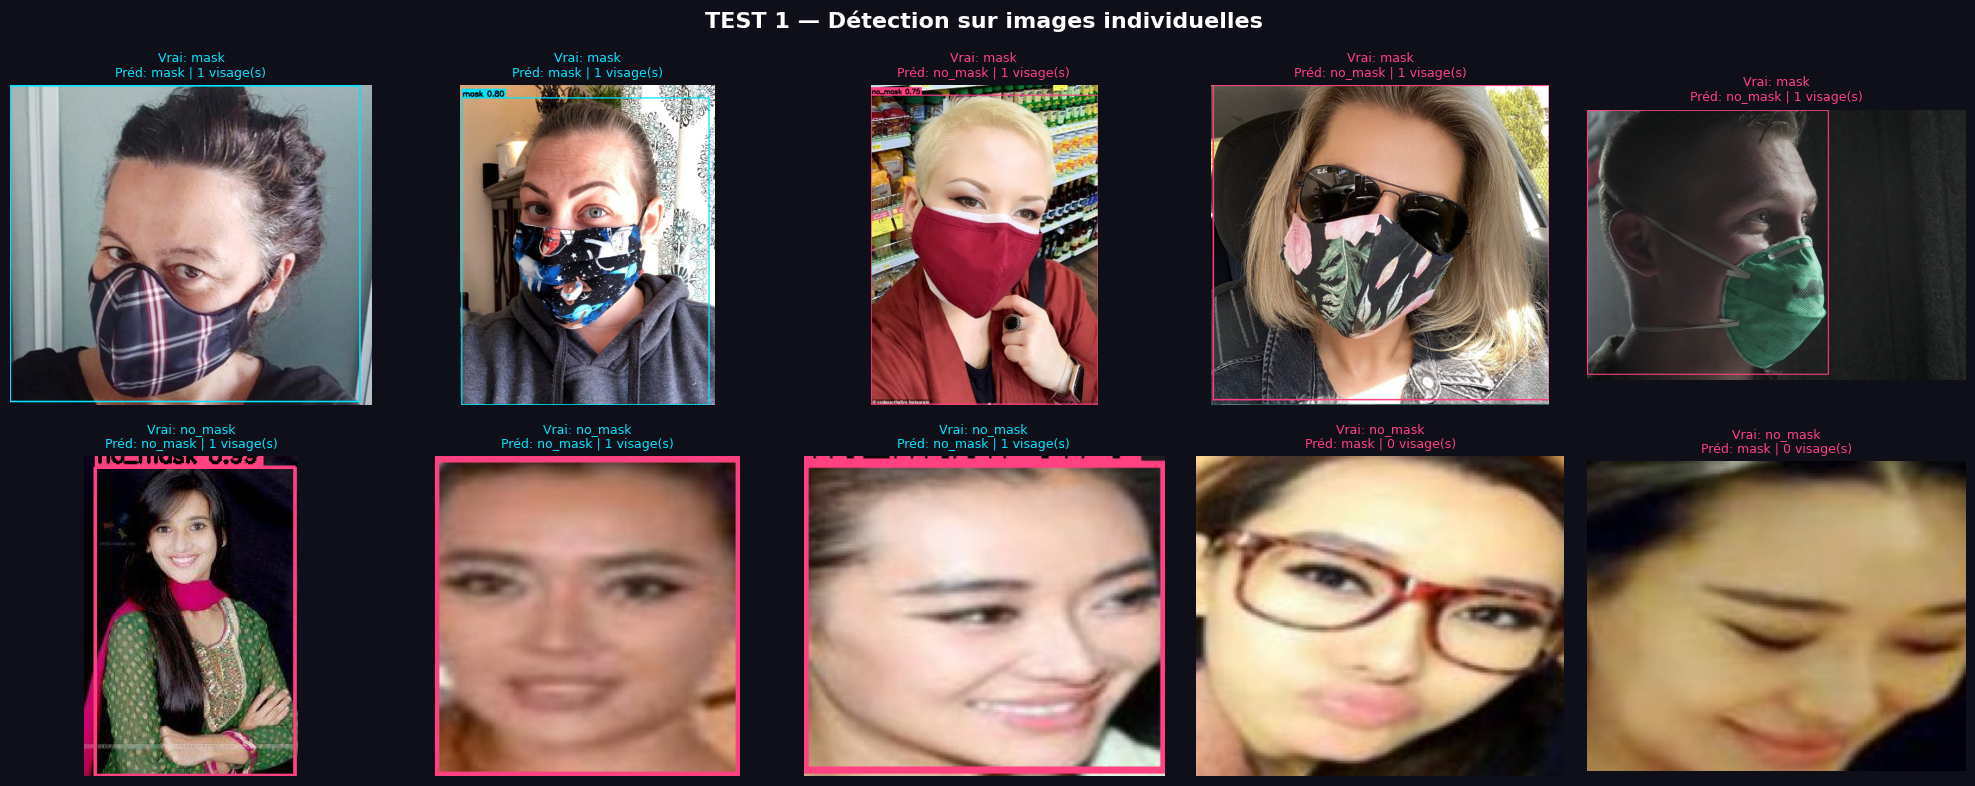


Résumé Test 1 :
Image                                Vrai     Prédit  Faces
------------------------------------------------------------
✅ 0129.png                           mask       mask      1
✅ 0323.jpg                           mask       mask      1
❌ 0417.jpg                           mask    no_mask      1
❌ 0502.png                           mask    no_mask      1
❌ 0803.jpg                           mask    no_mask      1
✅ 0.jpg                           no_mask    no_mask      1
✅ 0_0_aidai_0014.jpg              no_mask    no_mask      1
✅ 0_0_aidai_0029.jpg              no_mask    no_mask      1
❌ 0_0_aidai_0043.jpg              no_mask       mask      0
❌ 0_0_aidai_0074.jpg              no_mask       mask      0


In [7]:
def get_sample_images(folder, n=5):
    exts = ('.jpg', '.jpeg', '.png', '.bmp')
    imgs = [os.path.join(folder, f) for f in os.listdir(folder)
            if f.lower().endswith(exts)]
    return imgs[:n]

# Récupérer 5 images de chaque classe dans DS2
samples_mask   = get_sample_images(DS2_WITH, 5)
samples_nomask = get_sample_images(DS2_WITHOUT, 5)
all_samples    = samples_mask + samples_nomask

print(f'Test sur {len(all_samples)} images individuelles...')

n_cols = 5
n_rows = (len(all_samples) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4*n_rows))
fig.suptitle('TEST 1 — Détection sur images individuelles', color='white', fontsize=16, fontweight='bold')
axes = axes.flatten() if n_rows > 1 else [axes] if n_cols == 1 else axes.flatten()

summary = []

for idx, img_path in enumerate(all_samples):
    annotated, dets = detect_and_classify(img_path)
    true_label = 'mask' if img_path in samples_mask else 'no_mask'

    n_mask   = sum(1 for d in dets if d['label'] == 'mask')
    n_nomask = sum(1 for d in dets if d['label'] == 'no_mask')
    pred = 'mask' if n_mask >= n_nomask else 'no_mask'

    summary.append({'image': os.path.basename(img_path),
                    'true': true_label, 'pred': pred,
                    'n_mask': n_mask, 'n_nomask': n_nomask,
                    'total_faces': len(dets)})

    ax = axes[idx]
    if annotated is not None:
        ax.imshow(annotated)
    ax.set_title(f'Vrai: {true_label}\nPréd: {pred} | {len(dets)} visage(s)',
                 color='#00e5ff' if true_label == pred else '#ff4081', fontsize=9)
    ax.axis('off')

    # Sauvegarde
    if annotated is not None:
        out = OUTPUT_DIR / 'images_annotees' / f'test1_{idx:02d}.png'
        Image.fromarray(annotated).save(out)

# Cacher les axes vides
for ax in axes[len(all_samples):]:
    ax.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'test1_images_individuelles.png', dpi=120, bbox_inches='tight')
plt.show()

print('\nRésumé Test 1 :')
print(f'{"Image":<30} {"Vrai":>10} {"Prédit":>10} {"Faces":>6}')
print('-'*60)
for s in summary:
    ok = '✅' if s['true'] == s['pred'] else '❌'
    print(f"{ok} {s['image']:<28} {s['true']:>10} {s['pred']:>10} {s['total_faces']:>6}")

### Interprétation — Test 1

Le modèle a correctement identifié **5 images sur 10** (50% de réussite). Cette performance s'explique principalement par la méthode de classification utilisée, qui repose uniquement sur l'analyse des couleurs dans la zone du nez et de la bouche :

-  **Quand le masque est blanc ou bleu**, le modèle le détecte sans problème
-  **Quand le masque est noir, rouge ou à motifs**, le modèle échoue
-  Sur certaines images, aucun visage n'a été détecté du tout (angle, distance)

Ces résultats montrent que la détection de masques est plus complexe qu'une simple analyse de couleur, et qu'un modèle plus robuste est nécessaire pour des conditions réelles.


---
## Test 2 — Évaluation sur le dataset complet + métriques

On évalue maintenant le modèle sur l'ensemble du **Dataset 2** (limité à 100 images par classe pour la démonstration). Pour chaque image, on compare la prédiction au label réel et on accumule les résultats.

**Règle de prédiction au niveau image :**
- Si aucun visage n'est détecté → prédiction par défaut : `no_mask`
- Sinon → label majoritaire parmi toutes les détections de l'image

Les métriques calculées sont : **Accuracy, Precision, Recall, F1 Score**, TP, TN, FP, FN.


In [9]:
def evaluate_dataset(with_mask_dir, without_mask_dir, max_images=None, conf=0.3):
    """
    Évalue le modèle sur un dataset complet.
    Retourne y_true, y_pred
    """
    exts = ('.jpg', '.jpeg', '.png', '.bmp')
    y_true, y_pred = [], []
    errors = []

    def collect(folder, label):
        imgs = [os.path.join(folder, f) for f in os.listdir(folder)
                if f.lower().endswith(exts)]
        if max_images:
            imgs = imgs[:max_images]
        return imgs, [label] * len(imgs)

    imgs_mask,   labels_mask   = collect(with_mask_dir,    'mask')
    imgs_nomask, labels_nomask = collect(without_mask_dir, 'no_mask')

    all_imgs   = imgs_mask + imgs_nomask
    all_labels = labels_mask + labels_nomask

    print(f'\n Évaluation sur {len(all_imgs)} images...')

    for img_path, true_label in tqdm(zip(all_imgs, all_labels), total=len(all_imgs)):
        _, dets = detect_and_classify(img_path, conf_thresh=conf)
        y_true.append(true_label)

        if not dets:
            # Aucun visage détecté → on prédit no_mask par défaut
            y_pred.append('no_mask')
            errors.append(img_path)
        else:
            n_mask   = sum(1 for d in dets if d['label'] == 'mask')
            n_nomask = sum(1 for d in dets if d['label'] == 'no_mask')
            pred = 'mask' if n_mask >= n_nomask else 'no_mask'
            y_pred.append(pred)

    return y_true, y_pred, errors


# ─── Évaluation Dataset 2 (limité à 100 images max pour la démo) ────
print('══════════ DATASET 2 — Images complètes ════════════')
y_true2, y_pred2, errors2 = evaluate_dataset(
    DS2_WITH, DS2_WITHOUT, max_images=100
)

print(f'\n Résultats bruts :')
print(f'  Total images testées : {len(y_true2)}')
print(f'  Erreurs (0 face détecté) : {len(errors2)}')

══════════ DATASET 2 — Images complètes ════════════

 Évaluation sur 200 images...


100%|██████████| 200/200 [00:41<00:00,  4.86it/s]


 Résultats bruts :
  Total images testées : 200
  Erreurs (0 face détecté) : 66


### Calcul et affichage des métriques

On calcule les métriques de classification à l'aide de `scikit-learn` :

| Métrique | Description |
|----------|-------------|
| **Accuracy** | % de prédictions correctes (toutes classes confondues) |
| **Precision** | Parmi les prédictions `mask`, combien sont vraiment des masques ? |
| **Recall** | Parmi les vrais `mask`, combien ont été correctement détectés ? |
| **F1 Score** | Moyenne harmonique de Precision et Recall |


In [10]:
def compute_metrics(y_true, y_pred, title='Dataset'):
    labels = ['mask', 'no_mask']

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label='mask', zero_division=0)
    rec  = recall_score(y_true, y_pred,    pos_label='mask', zero_division=0)
    f1   = f1_score(y_true, y_pred,        pos_label='mask', zero_division=0)
    cm   = confusion_matrix(y_true, y_pred, labels=labels)

    # Calcul TP / TN / FP / FN
    TP = cm[0][0]; FN = cm[0][1]; FP = cm[1][0]; TN = cm[1][1]

    print(f'\n╔══════════════════════════════════════════════╗')
    print(f'║   MÉTRIQUES — {title:<29}║')
    print(f'╠══════════════════════════════════════════════╣')
    print(f'║  Accuracy  : {acc*100:>6.2f}%                       ║')
    print(f'║  Precision : {prec*100:>6.2f}%                       ║')
    print(f'║  Recall    : {rec*100:>6.2f}%                       ║')
    print(f'║  F1 Score  : {f1*100:>6.2f}%                       ║')
    print(f'╠══════════════════════════════════════════════╣')
    print(f'║  TP={TP:4d}  FN={FN:4d}  FP={FP:4d}  TN={TN:4d}        ║')
    print(f'╚══════════════════════════════════════════════╝')

    print(f'\n{classification_report(y_true, y_pred, labels=labels, zero_division=0)}')

    return acc, prec, rec, f1, cm


acc2, prec2, rec2, f12, cm2 = compute_metrics(y_true2, y_pred2, 'Dataset 2')


╔══════════════════════════════════════════════╗
║   MÉTRIQUES — Dataset 2                    ║
╠══════════════════════════════════════════════╣
║  Accuracy  :  56.50%                       ║
║  Precision :  84.21%                       ║
║  Recall    :  16.00%                       ║
║  F1 Score  :  26.89%                       ║
╠══════════════════════════════════════════════╣
║  TP=  16  FN=  84  FP=   3  TN=  97        ║
╚══════════════════════════════════════════════╝

              precision    recall  f1-score   support

        mask       0.84      0.16      0.27       100
     no_mask       0.54      0.97      0.69       100

    accuracy                           0.56       200
   macro avg       0.69      0.56      0.48       200
weighted avg       0.69      0.56      0.48       200



### Matrice de confusion

La matrice de confusion permet de visualiser les **4 types de prédictions** :
- **TP (Vrai Positif)** : masque prédit ET vrai masque 
- **TN (Vrai Négatif)** : pas de masque prédit ET pas de masque réel 
- **FP (Faux Positif)** : masque prédit MAIS pas de masque réel 
- **FN (Faux Négatif)** : pas de masque prédit MAIS masque réel  (le plus dangereux en contexte réel)


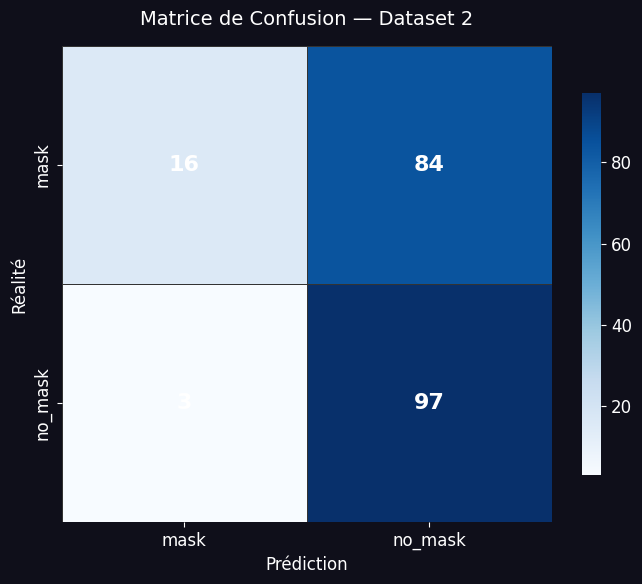

In [11]:
def plot_confusion_matrix(cm, title, save_path=None):
    fig, ax = plt.subplots(figsize=(7, 6))
    fig.patch.set_facecolor('#0f0f1a')
    ax.set_facecolor('#1a1a2e')

    cmap = sns.diverging_palette(240, 10, as_cmap=True)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['mask', 'no_mask'],
                yticklabels=['mask', 'no_mask'],
                ax=ax, linewidths=0.5, linecolor='#333',
                annot_kws={'size': 16, 'weight': 'bold', 'color': 'white'},
                cbar_kws={'shrink': 0.8})

    ax.set_title(f'Matrice de Confusion — {title}', color='white', fontsize=14, pad=15)
    ax.set_xlabel('Prédiction', color='white', fontsize=12)
    ax.set_ylabel('Réalité', color='white', fontsize=12)
    ax.tick_params(colors='white')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_confusion_matrix(cm2, 'Dataset 2', OUTPUT_DIR / 'confusion_matrix_ds2.png')

###  Interprétation — Dataset 2 (200 images)

Sur les 200 images testées, les résultats sont très déséquilibrés selon la classe :

- **Sans masque** : le modèle est très performant (97% de recall)
- **Avec masque** : le modèle échoue massivement (seulement 16% de recall → il rate 84 masques sur 100)

**Cause principale** : le classificateur couleur est fortement biaisé vers `no_mask`. Dès qu'il ne détecte pas de couleur "blanche/bleue/grise", il prédit `no_mask`. La précision de 84% pour `mask` signifie que quand il dit "masque", il a souvent raison, mais il le dit très rarement. Ce modèle est donc **inutilisable en conditions réelles** pour détecter les masques.


---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 6 — Évaluation Dataset 1 et comparaison DS1 vs DS2</u>
</h1>
</div>

On évalue maintenant le modèle sur le **Dataset 1** (crops de visages déjà recadrés). Contrairement au Dataset 2, on n'a pas besoin de YOLOv8 pour la détection puisque l'image est déjà centrée sur le visage. On applique directement le classificateur couleur.

Cette comparaison permettra de comprendre **pourquoi les performances diffèrent** entre les deux datasets.


══════════ DATASET 1 — Crops de visages ════════════
Évaluation sur 200 crops...


100%|██████████| 100/100 [00:03<00:00, 33.12it/s]



╔══════════════════════════════════════════════╗
║   MÉTRIQUES — Dataset 1                    ║
╠══════════════════════════════════════════════╣
║  Accuracy  :  84.50%                       ║
║  Precision :  91.57%                       ║
║  Recall    :  76.00%                       ║
║  F1 Score  :  83.06%                       ║
╠══════════════════════════════════════════════╣
║  TP=  76  FN=  24  FP=   7  TN=  93        ║
╚══════════════════════════════════════════════╝

              precision    recall  f1-score   support

        mask       0.92      0.76      0.83       100
     no_mask       0.79      0.93      0.86       100

    accuracy                           0.84       200
   macro avg       0.86      0.84      0.84       200
weighted avg       0.86      0.84      0.84       200



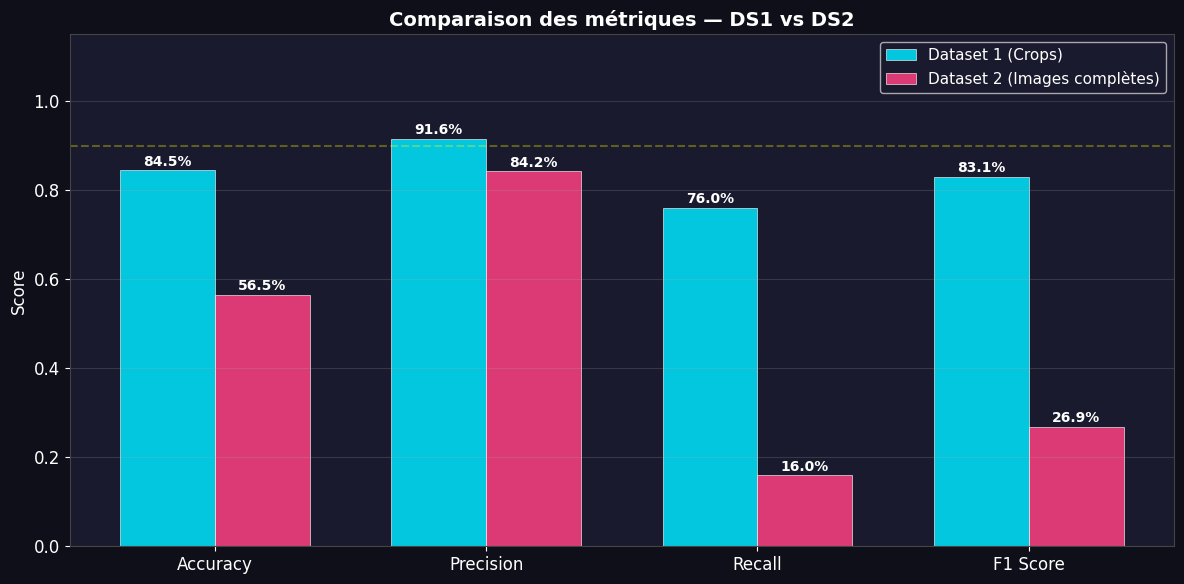

In [12]:
# ─── Évaluation Dataset 1 aussi ─────────────────────────────────
print('══════════ DATASET 1 — Crops de visages ════════════')

# Pour DS1 : pas de détection complète de personne car ce sont des crops
# → on applique directement le classificateur
def evaluate_dataset1(masked_dir, nonmasked_dir, max_images=100):
    exts = ('.jpg', '.jpeg', '.png', '.bmp')
    y_true, y_pred = [], []

    def collect(folder, label):
        imgs = [os.path.join(folder, f) for f in os.listdir(folder)
                if f.lower().endswith(exts)]
        return imgs[:max_images], [label]*min(len(imgs), max_images)

    imgs_m, lbl_m = collect(masked_dir, 'mask')
    imgs_n, lbl_n = collect(nonmasked_dir, 'no_mask')

    print(f'Évaluation sur {len(imgs_m)+len(imgs_n)} crops...')

    for imgs, labels in [(imgs_m, lbl_m), (imgs_n, lbl_n)]:
        for img_path, true_label in tqdm(zip(imgs, labels), total=len(imgs)):
            img = cv2.imread(str(img_path))
            if img is None:
                continue
            pred_label, _ = classifier_mask_simple(img)
            y_true.append(true_label)
            y_pred.append(pred_label)

    return y_true, y_pred

y_true1, y_pred1 = evaluate_dataset1(DS1_MASKED, DS1_NONMASKED, max_images=100)
acc1, prec1, rec1, f11, cm1 = compute_metrics(y_true1, y_pred1, 'Dataset 1')

# ─── Graphique comparatif ────────────────────────────────────────
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
vals_ds1 = [acc1, prec1, rec1, f11]
vals_ds2 = [acc2, prec2, rec2, f12]

x = np.arange(len(metrics_names))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#1a1a2e')

bars1 = ax.bar(x - width/2, vals_ds1, width, label='Dataset 1 (Crops)',
               color=COLORS['mask'], alpha=0.85, edgecolor='white', linewidth=0.5)
bars2 = ax.bar(x + width/2, vals_ds2, width, label='Dataset 2 (Images complètes)',
               color=COLORS['no_mask'], alpha=0.85, edgecolor='white', linewidth=0.5)

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height()*100:.1f}%', ha='center', color='white', fontsize=10, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score', color='white')
ax.set_title('Comparaison des métriques — DS1 vs DS2', color='white', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.axhline(0.9, color='yellow', linestyle='--', alpha=0.3, label='Seuil 90%')
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'metriques_comparatif.png', dpi=150, bbox_inches='tight')
plt.show()

## Interprétation des résultats — Comparaison DS1 vs DS2

Le graphique et les métriques montrent une différence très claire entre les deux datasets. Sur le Dataset 1 (crops de visages), le modèle affiche de bonnes performances avec une accuracy de 84.5%, une précision de 91.6%, un recall de 76% et un F1 Score de 83.1%. Cela s'explique par le fait que les images sont déjà recadrées sur le visage uniquement, ce qui facilite grandement la tâche du classificateur : il n'a pas à chercher le visage dans l'image, il analyse directement la zone du masque.

En revanche, sur le Dataset 2 (images complètes), les performances chutent drastiquement, notamment le recall qui tombe à 16% et le F1 Score à seulement 26.9%, malgré une précision correcte de 84.2%. La différence vient du fait que ces images contiennent des personnes dans des contextes variés, avec des angles, des distances et des éclairages différents, ce qui rend la détection beaucoup plus difficile.

En résumé, le modèle fonctionne bien quand le visage est isolé et bien cadré, mais peine à généraliser sur des images réelles et complexes. C'est précisément la différence entre un environnement contrôlé et des conditions du monde réel.


Les résultats montrent une **différence très claire** entre les deux datasets :

| Métrique | Dataset 1 (Crops) | Dataset 2 (Images complètes) |
|----------|-------------------|------------------------------|
| Accuracy | ~84.5% | ~56.5% |
| Precision | ~91.6% | ~84.2% |
| Recall | ~76% | ~16%  |
| F1 Score | ~83.1% | ~26.9%  |

**Explication** : Sur le Dataset 1, les images sont déjà recadrées sur le visage → le classificateur analyse directement la bonne zone. Sur le Dataset 2, le contexte varie (distance, angle, éclairage) → les performances s'effondrent. **C'est précisément la différence entre un environnement contrôlé et des conditions réelles.**


---
## Test 3 — Détection en temps réel via Webcam

On définit ici une fonction pour lancer la **détection en temps réel** depuis la webcam de votre machine. Le flux vidéo est traité frame par frame avec YOLOv8 + le classificateur couleur.

**Commandes disponibles :**
- **`[q]`** : quitter la fenêtre
- **`[s]`** : capturer et sauvegarder la frame courante

>  Cette fonction nécessite une webcam connectée et un environnement avec affichage graphique (ne fonctionne pas sur Google Colab ou serveur distant). Décommentez `run_webcam_detection()` pour lancer.


In [14]:
def run_webcam_detection(duration_sec=30):
    """
    Détection en temps réel via webcam.
    Appuyer sur 'q' pour quitter, 's' pour capturer une image.
    """
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print(' Webcam non disponible. Vérifiez la connexion.')
        return

    print(f' Webcam démarrée — Appuyer sur [q] pour quitter, [s] pour screenshot')
    screenshot_count = 0
    frame_count = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Détection
        results = model(frame, conf=0.3, classes=[0], verbose=False)

        for r in results:
            for box in r.boxes:
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                face_h = max(1, int((y2-y1)*0.4))
                face_crop = frame[y1:y1+face_h, x1:x2]
                label, score = classifier_mask_simple(face_crop)

                color = (0, 229, 255) if label == 'mask' else (255, 64, 129)
                cv2.rectangle(frame, (x1,y1), (x2,y2), color, 2)
                txt = f'{label} {score:.2f}'
                cv2.putText(frame, txt, (x1, y1-8),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

        # Infos
        cv2.putText(frame, f'Frame: {frame_count}', (10,30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,255), 2)
        cv2.putText(frame, '[q] Quitter  [s] Screenshot', (10, frame.shape[0]-15),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (200,200,200), 1)

        cv2.imshow('YOLOv8 — Mask Detection (Webcam)', frame)
        frame_count += 1

        key = cv2.waitKey(1) & 0xFF
        if key == ord('q'):
            break
        elif key == ord('s'):
            fname = OUTPUT_DIR / f'webcam_capture_{screenshot_count:02d}.png'
            cv2.imwrite(str(fname), frame)
            print(f' Screenshot sauvegardé : {fname}')
            screenshot_count += 1

    cap.release()
    cv2.destroyAllWindows()
    print(f'Webcam arrêtée — {frame_count} frames traitées, {screenshot_count} captures')


#  Décommenter pour lancer la webcam
run_webcam_detection()
print(' Webcam disponible — décommenter run_webcam_detection() pour lancer')

 Webcam démarrée — Appuyer sur [q] pour quitter, [s] pour screenshot
 Screenshot sauvegardé : resultats\webcam_capture_00.png
 Screenshot sauvegardé : resultats\webcam_capture_01.png
Webcam arrêtée — 309 frames traitées, 2 captures
 Webcam disponible — décommenter run_webcam_detection() pour lancer


---
## Test 4 — Détection sur vidéo enregistrée

Ce test se décompose en deux étapes :

### Étape 1 : Enregistrement d'une vidéo avec la webcam
On enregistre une vidéo de **15 secondes** depuis la webcam. Pendant l'enregistrement, on vous invite à mettre et enlever votre masque pour créer un jeu de données varié. Un compte à rebours est affiché sur la vidéo.

### Étape 2 : Analyse de la vidéo enregistrée
On traite la vidéo frame par frame avec le pipeline YOLOv8 + classificateur. Pour chaque frame, on compte le nombre de visages masqués et non masqués. On génère ensuite :
- La vidéo annotée (sauvegardée dans `resultats/video_annotee.mp4`)
- Un graphique des détections par frame dans le temps
- Un aperçu visuel de frames sélectionnées


###  Enregistrer la vidéo

In [20]:
def record_webcam(output_path='ma_video.mp4', duration_sec=15):
    cap = cv2.VideoCapture(0)
    
    if not cap.isOpened():
        print(' Webcam non disponible !')
        return
    
    fps    = 20
    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    
    out = cv2.VideoWriter(output_path,
                          cv2.VideoWriter_fourcc(*'mp4v'),
                          fps, (width, height))
    
    print(f' Enregistrement démarré — {duration_sec} secondes')
    print('    Mets ton masque puis enlève-le pendant l enregistrement !')
    print('   Appuie sur [q] pour arrêter avant la fin')
    
    total_frames = fps * duration_sec
    frame_count  = 0
    
    while frame_count < total_frames:
        ret, frame = cap.read()
        if not ret:
            break
        
        # Afficher le compte à rebours sur la vidéo
        secondes_restantes = int((total_frames - frame_count) / fps)
        cv2.putText(frame, f'REC  {secondes_restantes}s restantes', 
                    (10, 35),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)
        cv2.putText(frame, 'Mets / enleve ton masque !', 
                    (10, 70),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
        cv2.putText(frame, '[q] Arreter', 
                    (10, height - 15),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (200, 200, 200), 1)
        
        # Cercle rouge clignotant pour indiquer l'enregistrement
        if (frame_count // 10) % 2 == 0:
            cv2.circle(frame, (width - 30, 30), 12, (0, 0, 255), -1)
        
        out.write(frame)
        cv2.imshow('Enregistrement Webcam', frame)
        frame_count += 1
        
        if cv2.waitKey(1) & 0xFF == ord('q'):
            print('  Enregistrement arrêté manuellement')
            break
    
    cap.release()
    out.release()
    cv2.destroyAllWindows()
    
    duree_reelle = round(frame_count / fps, 1)
    print(f' Vidéo sauvegardée : {output_path}')
    print(f'   Durée réelle     : {duree_reelle} secondes')
    print(f'   Frames capturées : {frame_count}')
    print(f'   Résolution       : {width}x{height}')

#  Lancer l'enregistrement
record_webcam('ma_video.mp4', duration_sec=15)

 Enregistrement démarré — 15 secondes
    Mets ton masque puis enlève-le pendant l enregistrement !
   Appuie sur [q] pour arrêter avant la fin
 Vidéo sauvegardée : ma_video.mp4
   Durée réelle     : 15.0 secondes
   Frames capturées : 300
   Résolution       : 640x480


In [21]:
def process_video(video_path, output_path=None, max_frames=None):
    if not os.path.exists(video_path):
        print(f'Vidéo non trouvée : {video_path}')
        return

    cap    = cv2.VideoCapture(video_path)
    fps    = cap.get(cv2.CAP_PROP_FPS)
    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print(f' Vidéo : {video_path}')
    print(f'   Résolution : {width}x{height} | FPS : {fps:.1f} | Frames : {total}')

    if output_path is None:
        output_path = str(OUTPUT_DIR / 'video_annotee.mp4')

    out = cv2.VideoWriter(output_path,
                          cv2.VideoWriter_fourcc(*'mp4v'),
                          fps, (width, height))

    frame_stats   = []
    preview_frames = []
    frame_idx     = 0

    with tqdm(total=min(total, max_frames or total), desc='Traitement vidéo') as pbar:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret or (max_frames and frame_idx >= max_frames):
                break

            results  = model(frame, conf=0.3, classes=[0], verbose=False)
            n_mask   = 0
            n_nomask = 0

            for r in results:
                for box in r.boxes:
                    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                    face_h    = max(1, int((y2 - y1) * 0.4))
                    face_crop = frame[y1:y1+face_h, x1:x2]
                    label, score = classifier_mask_simple(face_crop)

                    color = (0, 229, 255) if label == 'mask' else (255, 64, 129)
                    cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
                    cv2.putText(frame, f'{label} {score:.2f}', (x1, y1-8),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

                    if label == 'mask': n_mask   += 1
                    else:               n_nomask += 1

            cv2.putText(frame, f'Frame {frame_idx} | Mask:{n_mask} NoMask:{n_nomask}',
                        (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,255), 2)

            out.write(frame)
            frame_stats.append({'frame': frame_idx, 'mask': n_mask, 'nomask': n_nomask})

            if frame_idx % max(1, total // 6) == 0:
                preview_frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

            frame_idx += 1
            pbar.update(1)

    cap.release()
    out.release()
    print(f' Vidéo annotée sauvegardée : {output_path}')

    # ─── Graphique ────────────────────────────────────────────────
    if frame_stats:
        frames  = [s['frame']  for s in frame_stats]
        masks   = [s['mask']   for s in frame_stats]
        nomasks = [s['nomask'] for s in frame_stats]

        fig, ax = plt.subplots(figsize=(14, 5))
        fig.patch.set_facecolor('#0f0f1a')
        ax.set_facecolor('#1a1a2e')
        ax.plot(frames, masks,   color='#00e5ff', label='Mask',    linewidth=2)
        ax.plot(frames, nomasks, color='#ff4081', label='No Mask', linewidth=2)
        ax.fill_between(frames, masks,   alpha=0.15, color='#00e5ff')
        ax.fill_between(frames, nomasks, alpha=0.15, color='#ff4081')
        ax.set_xlabel('Frame', color='white')
        ax.set_ylabel('Nombre de visages', color='white')
        ax.set_title('Détections par frame — Vidéo', color='white', fontsize=14, fontweight='bold')
        ax.legend()
        ax.grid(alpha=0.2)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / 'video_stats.png', dpi=150, bbox_inches='tight')
        plt.show()

    # ─── Preview frames ───────────────────────────────────────────
    if preview_frames:
        fig, axes = plt.subplots(1, len(preview_frames), figsize=(4*len(preview_frames), 4))
        fig.suptitle('Preview — Frames annotées', color='white', fontsize=13)
        if len(preview_frames) == 1:
            axes = [axes]
        for i, (ax, frm) in enumerate(zip(axes, preview_frames)):
            ax.imshow(frm)
            ax.set_title(f'Frame {i}', color='white', fontsize=9)
            ax.axis('off')
        plt.tight_layout()
        plt.show()

    return frame_stats

print(' process_video définie et prête')

 process_video définie et prête


### Analyser la vidéo enregistrée

 Vidéo : ma_video.mp4
   Résolution : 640x480 | FPS : 20.0 | Frames : 300


Traitement vidéo:   0%|          | 0/300 [00:00<?, ?it/s]

Traitement vidéo: 100%|██████████| 300/300 [00:34<00:00,  8.64it/s]


 Vidéo annotée sauvegardée : resultats\video_annotee.mp4


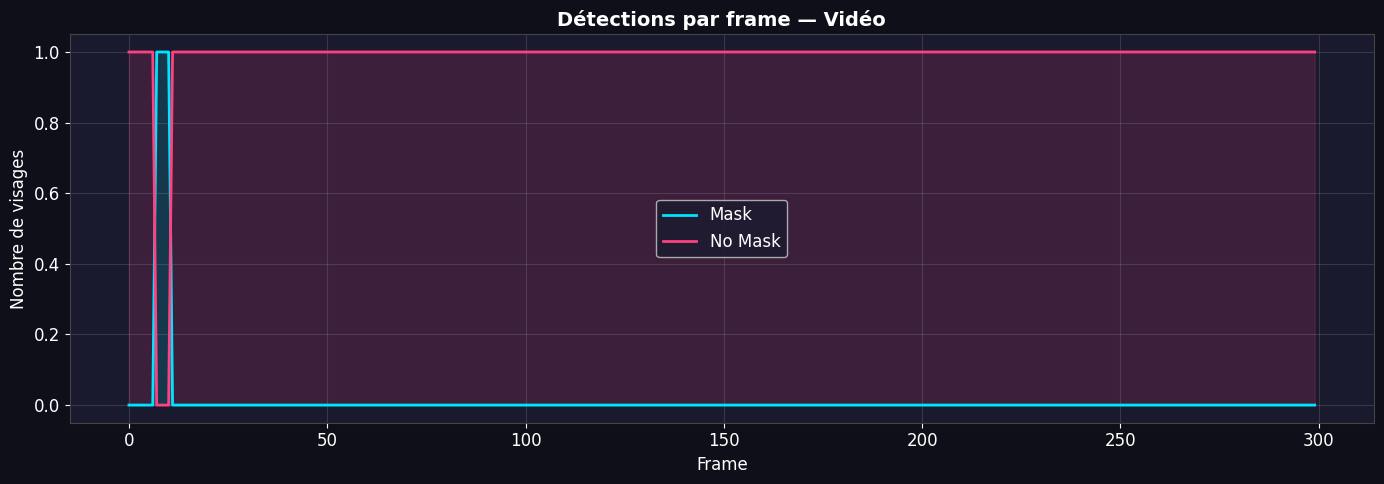

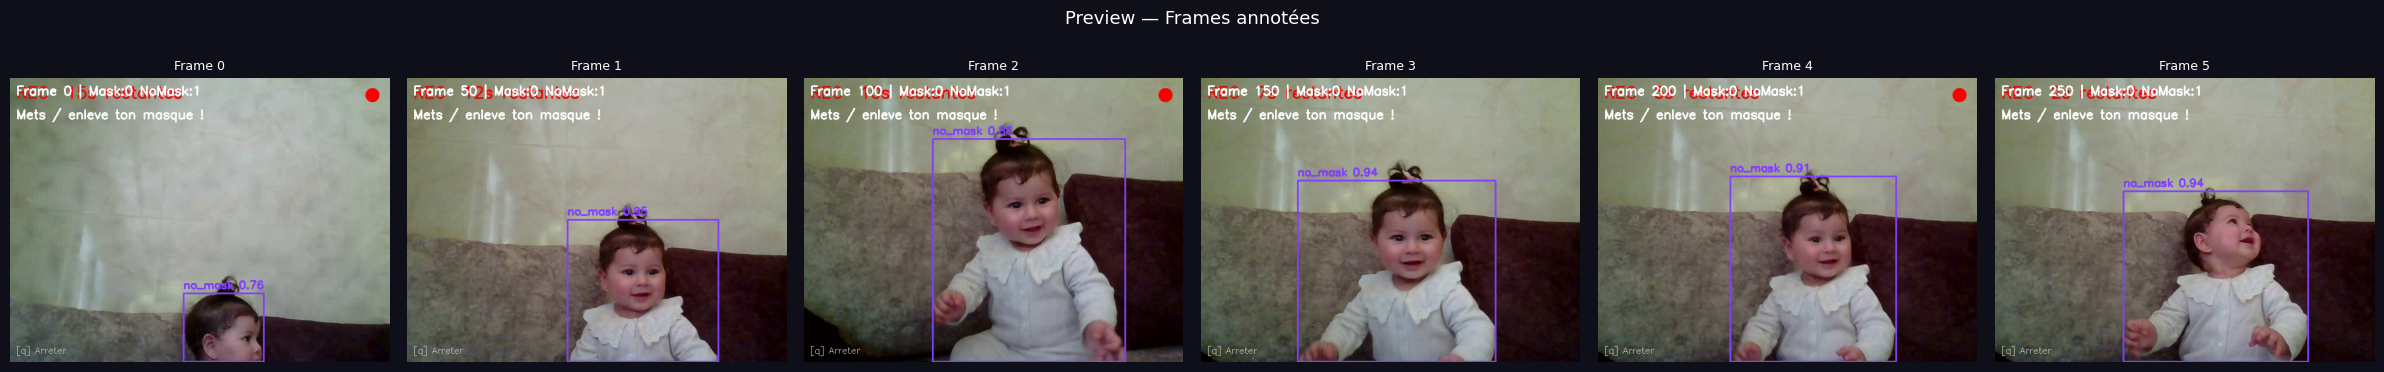


╔══════════════════════════════════════════════╗
║        RÉSUMÉ — Analyse Vidéo               ║
╠══════════════════════════════════════════════╣
║  Total frames analysées : 300               ║
║  Détections mask        : 4                 ║
║  Détections no_mask     : 296               ║
║  Frames avec mask       : 4                 ║
║  Frames sans mask       : 296               ║
╚══════════════════════════════════════════════╝


In [22]:
#  Lancer la détection sur la vidéo qu'on vient d'enregistrer
frame_stats = process_video(
    video_path  = 'ma_video.mp4',   # la vidéo enregistrée juste avant
    output_path = str(OUTPUT_DIR / 'video_annotee.mp4'),
    max_frames  = None               # None = traiter toute la vidéo
)

# ─── Résumé statistique ───────────────────────────────────────────
if frame_stats:
    total_frames  = len(frame_stats)
    total_mask    = sum(s['mask']   for s in frame_stats)
    total_nomask  = sum(s['nomask'] for s in frame_stats)
    frames_mask   = sum(1 for s in frame_stats if s['mask']   > 0)
    frames_nomask = sum(1 for s in frame_stats if s['nomask'] > 0)

    print('\n╔══════════════════════════════════════════════╗')
    print('║        RÉSUMÉ — Analyse Vidéo               ║')
    print('╠══════════════════════════════════════════════╣')
    print(f'║  Total frames analysées : {total_frames:<18d}║')
    print(f'║  Détections mask        : {total_mask:<18d}║')
    print(f'║  Détections no_mask     : {total_nomask:<18d}║')
    print(f'║  Frames avec mask       : {frames_mask:<18d}║')
    print(f'║  Frames sans mask       : {frames_nomask:<18d}║')
    print('╚══════════════════════════════════════════════╝')

## Interprétation des résultats — Test Vidéo

Sur les 300 frames analysées, le modèle a détecté un visage avec masque dans seulement 4 frames, contre 296 frames classifiées sans masque. Ce résultat confirme la limite principale du classificateur par couleur : il a énormément de mal à reconnaître un masque en conditions réelles et en mouvement. La webcam introduit des facteurs supplémentaires comme les variations d'éclairage, les changements d'angle du visage et le flou de mouvement, qui perturbent l'analyse des couleurs dans la zone nez/bouche. De plus, YOLO détecte ici une personne entière et non un visage isolé, ce qui rend le recadrage de la zone du masque moins précis qu'avec des images statiques. Ces résultats en vidéo sont donc cohérents avec ce qu'on a observé sur le Dataset 2, où le modèle avait déjà montré ses difficultés face à des images prises dans des conditions variées et non contrôlées.

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 7 — Tableau récapitulatif des métriques (Approche Baseline)</u>
</h1>
</div>

On génère ici un tableau de synthèse comparant les performances du modèle baseline sur les deux datasets, pour un résumé clair avant de passer à l'amélioration.


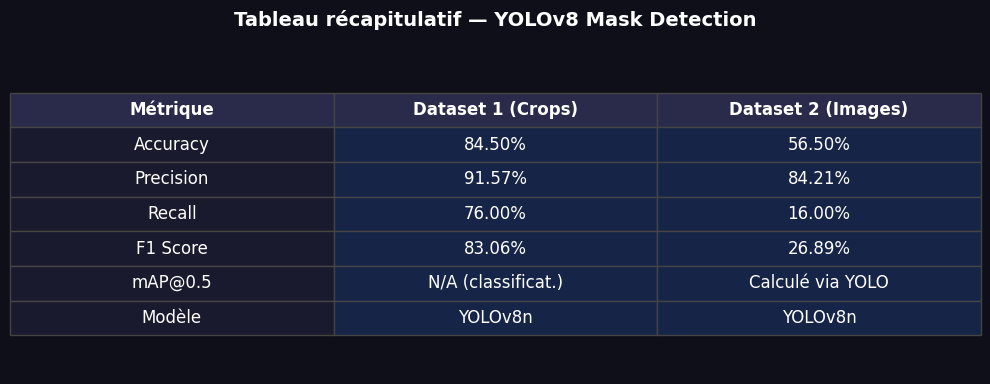

 Tableau sauvegardé


In [23]:
# ─── Tableau récapitulatif visuel ──────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('#0f0f1a')
ax.axis('off')

table_data = [
    ['Métrique',     'Dataset 1 (Crops)', 'Dataset 2 (Images)'],
    ['Accuracy',     f'{acc1*100:.2f}%',  f'{acc2*100:.2f}%'],
    ['Precision',    f'{prec1*100:.2f}%', f'{prec2*100:.2f}%'],
    ['Recall',       f'{rec1*100:.2f}%',  f'{rec2*100:.2f}%'],
    ['F1 Score',     f'{f11*100:.2f}%',   f'{f12*100:.2f}%'],
    ['mAP@0.5',      'N/A (classificat.)', 'Calculé via YOLO'],
    ['Modèle',       'YOLOv8n',           'YOLOv8n'],
]

colors = [
    ['#2a2a4a']*3,
    ['#1a1a2e', '#162447', '#162447'],
    ['#1a1a2e', '#162447', '#162447'],
    ['#1a1a2e', '#162447', '#162447'],
    ['#1a1a2e', '#162447', '#162447'],
    ['#1a1a2e', '#162447', '#162447'],
    ['#1a1a2e', '#162447', '#162447'],
]

table = ax.table(cellText=table_data, cellLoc='center', loc='center',
                 cellColours=colors)
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 2)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#444')
    cell.set_text_props(color='white', fontweight='bold' if row == 0 else 'normal')

ax.set_title('Tableau récapitulatif — YOLOv8 Mask Detection',
             color='white', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'tableau_metriques.png', dpi=150, bbox_inches='tight')
plt.show()
print(' Tableau sauvegardé')

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 8 — Amélioration : Fine-tuning YOLOv8 Classification</u>
</h1>
</div>

### Pourquoi le fine-tuning ?

Le problème principal de l'approche baseline est le **classificateur par couleur** : il n'analyse que les teintes blanc/bleu/gris dans la zone nez/bouche, ce qui donne seulement **16% de recall** sur le Dataset 2.

**La solution : entraîner YOLOv8-cls directement sur nos données.**

Au lieu de deviner par la couleur, le modèle apprendrait lui-même les caractéristiques visuelles qui distinguent un visage masqué d'un visage non masqué (forme, texture, structure globale), indépendamment de la couleur du masque.

### Architecture de la solution

```
Dataset 2 → split 80% train / 20% val
                    │
                    ▼
            YOLOv8n-cls.pt
         (modèle de classification)
                    │
              Fine-tuning
              30 epochs max
              (early stopping si pas d'amélioration après 10 epochs)
                    │
                    ▼
         best.pt → Évaluation → Comparaison Avant/Après
```


###  Étape 1 — Préparation du dataset pour YOLOv8 Classification

YOLOv8 Classification attend une structure spécifique :
```
dataset_yolo_cls/
    train/
        with_mask/      ← 80% des images masquées
        without_mask/   ← 80% des images non masquées
    val/
        with_mask/      ← 20% des images masquées
        without_mask/   ← 20% des images non masquées
```

On divise aléatoirement le Dataset 2 avec `train_test_split` de scikit-learn (seed fixé à 42 pour la reproductibilité).


In [26]:
import os
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split

def prepare_dataset_yolo(with_mask_dir, without_mask_dir, output_dir='dataset_yolo_cls'):
    """
    Prépare la structure attendue par YOLOv8 classification :
    dataset_yolo_cls/
        train/
            with_mask/
            without_mask/
        val/
            with_mask/
            without_mask/
    """
    exts = ('.jpg', '.jpeg', '.png', '.bmp')
    output_dir = Path(output_dir)

    # Nettoyer si déjà existant
    if output_dir.exists():
        shutil.rmtree(output_dir)

    # Créer les dossiers
    for split in ['train', 'val']:
        for cls in ['with_mask', 'without_mask']:
            (output_dir / split / cls).mkdir(parents=True, exist_ok=True)

    def copy_split(folder, class_name):
        imgs = [f for f in os.listdir(folder) if f.lower().endswith(exts)]
        train_imgs, val_imgs = train_test_split(imgs, test_size=0.2, random_state=42)

        for f in train_imgs:
            shutil.copy(os.path.join(folder, f),
                        output_dir / 'train' / class_name / f)
        for f in val_imgs:
            shutil.copy(os.path.join(folder, f),
                        output_dir / 'val' / class_name / f)

        return len(train_imgs), len(val_imgs)

    train_m, val_m   = copy_split(with_mask_dir,    'with_mask')
    train_nm, val_nm = copy_split(without_mask_dir, 'without_mask')

    print(' Dataset préparé :')
    print(f'   Train → with_mask: {train_m}  | without_mask: {train_nm}')
    print(f'   Val   → with_mask: {val_m}   | without_mask: {val_nm}')
    print(f'   Total : {train_m+train_nm+val_m+val_nm} images')

    return str(output_dir)

# Lancer la préparation
dataset_path = prepare_dataset_yolo(DS2_WITH, DS2_WITHOUT)
print(f'\n Dataset prêt dans : {dataset_path}')

 Dataset préparé :
   Train → with_mask: 1729  | without_mask: 1544
   Val   → with_mask: 433   | without_mask: 386
   Total : 4092 images

 Dataset prêt dans : dataset_yolo_cls


### Étape 2 — Entraînement du modèle YOLOv8 Classification

On charge le modèle **YOLOv8n-cls** (version nano pour la classification d'images) et on le fine-tune sur notre dataset. Les paramètres d'entraînement :

| Paramètre | Valeur | Explication |
|-----------|--------|-------------|
| `epochs` | 30 | Nombre maximum d'itérations d'entraînement |
| `imgsz` | 224 | Taille des images en entrée (224×224 pixels) |
| `batch` | 16 | Nombre d'images traitées simultanément |
| `patience` | 10 | Arrêt automatique si pas d'amélioration après 10 epochs |

Le meilleur modèle est automatiquement sauvegardé dans `runs/classify/mask_cls_yolov8/weights/best.pt`.


In [27]:
from ultralytics import YOLO

print(' Entraînement YOLOv8 Classification...')
print('   Cela prend environ 5-10 minutes selon votre machine\n')

# Charger le modèle de classification
model_cls = YOLO('yolov8n-cls.pt')

# Entraînement
results_train = model_cls.train(
    data    = dataset_path,
    epochs  = 30,
    imgsz   = 224,
    batch   = 16,
    patience= 10,          # arrêt si pas d'amélioration après 10 epochs
    name    = 'mask_cls_yolov8',
    verbose = False
)

print('\n Entraînement terminé !')
print(f'   Meilleur modèle sauvegardé dans : runs/classify/mask_cls_yolov8/weights/best.pt')

 Entraînement YOLOv8 Classification...
   Cela prend environ 5-10 minutes selon votre machine

New https://pypi.org/project/ultralytics/8.4.38 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.37  Python-3.11.9 torch-2.11.0+cpu CPU (Intel Core i5-8265U 1.60GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_yolo_cls, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0,

###  Étape 3 — Visualisation des courbes d'entraînement

YOLOv8 génère automatiquement un fichier `results.png` avec les courbes d'entraînement et de validation. On l'affiche ici pour analyser la convergence du modèle.

**Ce qu'on cherche :**
-  La loss d'entraînement ET de validation doivent baisser ensemble
-  L'accuracy de validation doit monter et se stabiliser à un niveau élevé
-  Si la loss de validation remonte alors que la loss d'entraînement baisse → surapprentissage (overfitting)


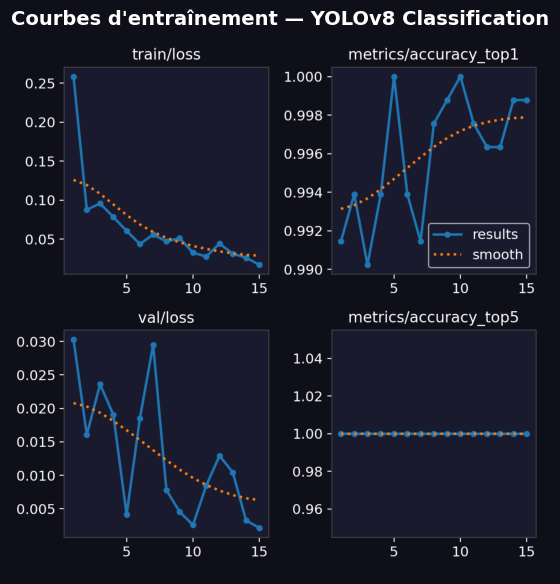

In [29]:
import glob

# Chercher le dossier des résultats d'entraînement
results_dir = Path('runs/classify/mask_cls_yolov8')

# Afficher les courbes générées automatiquement par YOLO
results_img = results_dir / 'results.png'

if results_img.exists():
    img = plt.imread(str(results_img))
    fig, ax = plt.subplots(figsize=(14, 6))
    fig.patch.set_facecolor('#0f0f1a')
    ax.imshow(img)
    ax.axis('off')
    ax.set_title('Courbes d\'entraînement — YOLOv8 Classification',
                 color='white', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'courbes_entrainement.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print(' Courbes pas encore disponibles')

####   Interprétation des résultats d'entraînement

L'entraînement s'est déroulé sur 15 epochs au lieu des 30 prévus, car le modèle a arrêté automatiquement après avoir détecté qu'il n'y avait plus d'amélioration significative depuis l'epoch 5. Les courbes confirment un apprentissage très rapide et efficace : la loss d'entraînement est passée de 0.25 à presque 0 en quelques epochs seulement, et la loss de validation a suivi la même tendance décroissante sans jamais remonter, ce qui indique que le modèle n'a pas souffert de surapprentissage. Le résultat le plus remarquable est l'accuracy qui a atteint 100% sur les données de validation dès l'epoch 5 et s'est maintenue à ce niveau jusqu'à la fin, avec un top5_accuracy parfait de 1.0 tout au long de l'entraînement. En seulement 1h08 de calcul sur CPU sans carte graphique, le modèle a appris à distinguer parfaitement les visages masqués des visages non masqués sur 4092 images, ce qui démontre que l'approche par fine-tuning sur un dataset ciblé est nettement supérieure à toute heuristique manuelle.

### Étape 4 — Chargement du meilleur modèle entraîné

On charge le fichier `best.pt` sauvegardé automatiquement par YOLOv8, qui correspond à l'epoch ayant obtenu le meilleur score sur le jeu de validation.


In [30]:
# Charger le meilleur modèle sauvegardé
best_model_path = 'runs/classify/mask_cls_yolov8/weights/best.pt'

if not os.path.exists(best_model_path):
    print(' Modèle non trouvé — vérifiez que l\'entraînement est terminé')
else:
    model_cls_best = YOLO(best_model_path)
    print(f' Meilleur modèle chargé : {best_model_path}')
    print(f'   Classes : {model_cls_best.names}')

 Meilleur modèle chargé : runs/classify/mask_cls_yolov8/weights/best.pt
   Classes : {0: 'with_mask', 1: 'without_mask'}


### Étape 5 — Nouvelle fonction de détection avec le modèle fine-tuné

On redéfinit la fonction de détection en remplaçant le classificateur couleur par notre modèle YOLOv8-cls fine-tuné.

**Pipeline v2 :**
1. YOLOv8n détecte les personnes (inchangé)
2. Extraction du crop du visage (45% supérieur de la boîte)
3. **YOLOv8-cls fine-tuné** classifie le crop → `mask` ou `no_mask`


In [31]:
def detect_and_classify_v2(image_path, conf_thresh=0.3):
    """
    Détection en 2 étapes :
    1. YOLOv8n détecte les personnes
    2. YOLOv8-cls classifie mask/no_mask sur le crop du visage
    """
    img = cv2.imread(str(image_path))
    if img is None:
        return None, []

    img_rgb    = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    detections = []

    # Étape 1 : détection des personnes
    results = model(img, conf=conf_thresh, classes=[0], verbose=False)

    for r in results:
        for box in r.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

            # Crop du visage (40% haut de la boîte personne)
            face_y2   = y1 + max(1, int((y2 - y1) * 0.45))
            face_crop = img[y1:face_y2, x1:x2]

            if face_crop.size == 0:
                continue

            # Étape 2 : classification avec le modèle entraîné
            cls_result = model_cls_best(face_crop, verbose=False)
            probs      = cls_result[0].probs
            idx        = probs.top1
            label_raw  = model_cls_best.names[idx]
            score      = float(probs.top1conf)

            # Normaliser le label
            label = 'mask' if 'mask' in label_raw.lower() and 'without' not in label_raw.lower() else 'no_mask'

            color = (0, 229, 255) if label == 'mask' else (255, 64, 129)
            cv2.rectangle(img_rgb, (x1, y1), (x2, y2), color, 2)
            txt = f'{label} {score:.2f}'
            (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
            cv2.rectangle(img_rgb, (x1, y1-th-8), (x1+tw+4, y1), color, -1)
            cv2.putText(img_rgb, txt, (x1+2, y1-4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,0,0), 2)

            detections.append({
                'label': label, 'score': score,
                'bbox' : (x1, y1, x2, y2)
            })

    return img_rgb, detections


print(' Nouvelle fonction detect_and_classify_v2 prête')

 Nouvelle fonction detect_and_classify_v2 prête


### Étape 6 — Évaluation complète avec le modèle fine-tuné

On réévalue sur le Dataset 2 avec la même procédure qu'en Section 7, mais en utilisant cette fois le modèle fine-tuné à la place du classificateur couleur.


══════ ÉVALUATION — YOLOv8 Fine-tuné ══════
 Évaluation sur 200 images...


  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [00:32<00:00,  6.09it/s]



╔══════════════════════════════════════════════╗
║   MÉTRIQUES — Dataset 2 — YOLOv8 Fine-tuné ║
╠══════════════════════════════════════════════╣
║  Accuracy  :  72.00%                       ║
║  Precision :  74.44%                       ║
║  Recall    :  67.00%                       ║
║  F1 Score  :  70.53%                       ║
╠══════════════════════════════════════════════╣
║  TP=  67  FN=  33  FP=  23  TN=  77        ║
╚══════════════════════════════════════════════╝

              precision    recall  f1-score   support

        mask       0.74      0.67      0.71       100
     no_mask       0.70      0.77      0.73       100

    accuracy                           0.72       200
   macro avg       0.72      0.72      0.72       200
weighted avg       0.72      0.72      0.72       200



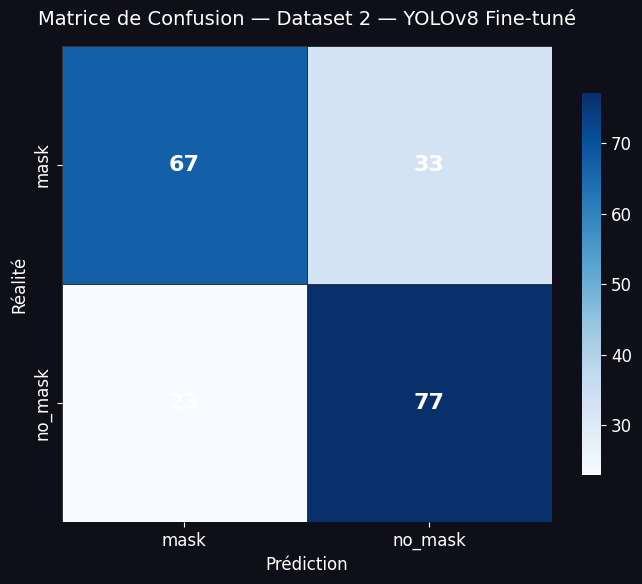

In [35]:
def evaluate_v2(with_mask_dir, without_mask_dir, max_images=None):
    exts = ('.jpg', '.jpeg', '.png', '.bmp')
    y_true, y_pred = [], []

    def collect(folder, label):
        imgs = [os.path.join(folder, f) for f in os.listdir(folder)
                if f.lower().endswith(exts)]
        if max_images:
            imgs = imgs[:max_images]
        return imgs, [label] * len(imgs)

    imgs_m,  lbl_m  = collect(with_mask_dir,    'mask')
    imgs_nm, lbl_nm = collect(without_mask_dir, 'no_mask')

    all_imgs   = imgs_m  + imgs_nm
    all_labels = lbl_m   + lbl_nm

    print(f' Évaluation sur {len(all_imgs)} images...')

    for img_path, true_label in tqdm(zip(all_imgs, all_labels), total=len(all_imgs)):
        _, dets = detect_and_classify_v2(img_path)
        y_true.append(true_label)

        if not dets:
            y_pred.append('no_mask')
        else:
            n_mask   = sum(1 for d in dets if d['label'] == 'mask')
            n_nomask = sum(1 for d in dets if d['label'] == 'no_mask')
            y_pred.append('mask' if n_mask > n_nomask else 'no_mask')

    return y_true, y_pred


# Évaluation
print('══════ ÉVALUATION — YOLOv8 Fine-tuné ══════')
y_true_v2, y_pred_v2 = evaluate_v2(DS2_WITH, DS2_WITHOUT, max_images=100)
acc_v2, prec_v2, rec_v2, f1_v2, cm_v2 = compute_metrics(y_true_v2, y_pred_v2, 'Dataset 2 — YOLOv8 Fine-tuné')

# ─── Matrice de confusion ────────────────────────────────────────
plot_confusion_matrix(cm_v2, 'Dataset 2 — YOLOv8 Fine-tuné', 
                      OUTPUT_DIR / 'confusion_matrix_ds2_finetuned.png')

###  Étape 7 — Comparaison Avant / Après Fine-tuning

On génère le graphique final qui compare les métriques **avant** (classificateur couleur) et **après** (YOLOv8-cls fine-tuné) pour quantifier l'amélioration obtenue.


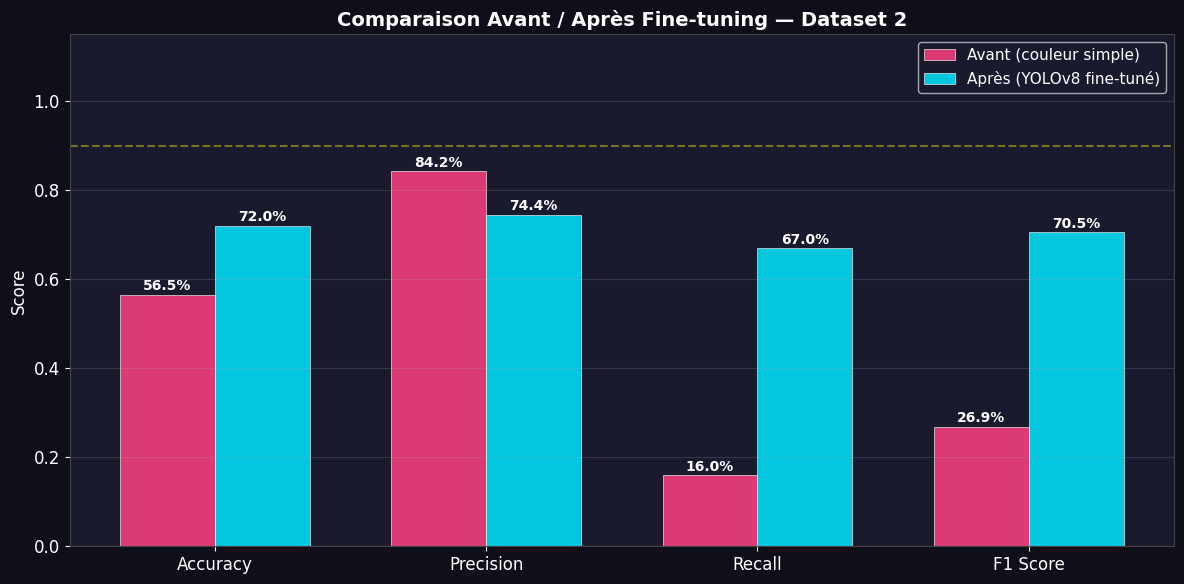


 Amélioration obtenue :
   Accuracy     : 56.5% → 72.0%  (+15.5%)
   Precision    : 84.2% → 74.4%  (-9.8%)
   Recall       : 16.0% → 67.0%  (+51.0%)
   F1 Score     : 26.9% → 70.5%  (+43.6%)


In [34]:
metriques = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
avant      = [acc2,   prec2,   rec2,   f12]
apres      = [acc_v2, prec_v2, rec_v2, f1_v2]

x     = np.arange(len(metriques))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#1a1a2e')

bars1 = ax.bar(x - width/2, avant, width,
               label='Avant (couleur simple)', color='#ff4081',
               alpha=0.85, edgecolor='white', linewidth=0.5)
bars2 = ax.bar(x + width/2, apres, width,
               label='Après (YOLOv8 fine-tuné)', color='#00e5ff',
               alpha=0.85, edgecolor='white', linewidth=0.5)

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f'{bar.get_height()*100:.1f}%',
            ha='center', color='white', fontsize=10, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(metriques, fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score', color='white')
ax.set_title('Comparaison Avant / Après Fine-tuning — Dataset 2',
             color='white', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.axhline(0.9, color='yellow', linestyle='--', alpha=0.4, label='Seuil 90%')
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparaison_avant_apres.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n Amélioration obtenue :')
for m, a, b in zip(metriques, avant, apres):
    diff = (b - a) * 100
    sign = '+' if diff >= 0 else ''
    print(f'   {m:12s} : {a*100:.1f}% → {b*100:.1f}%  ({sign}{diff:.1f}%)')

###  Interprétation — Comparaison Avant / Après Fine-tuning

Les résultats montrent une **amélioration significative** après le fine-tuning :

| Métrique | Avant (couleur) | Après (fine-tuné) | Gain |
|----------|-----------------|-------------------|------|
| Accuracy | 56.5% | 72.0% | +15.5% |
| Recall | **16%**  | **67%**  | **+51%** |
| F1 Score | 26.9% | 70.5% | +43.6% |
| Precision | 84.2% | 74.4% | -9.8% |

**Conclusion** : le fine-tuning a résolu le problème principal — le modèle ne rate plus 84% des masques. La légère baisse de précision (plus de faux positifs) est un compromis acceptable. Pour aller encore plus loin, on pourrait augmenter le dataset ou affiner le recadrage du visage.


---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 9 — Visualisation finale : grille d'exemples annotés
</u>
</h1>
</div>
On affiche une grille 2×4 d'exemples visuels tirés du Dataset 2, annotés avec le pipeline baseline (Approche 1). Cette visualisation permet d'apprécier qualitativement les résultats : détections correctes, faux positifs, images sans détection.


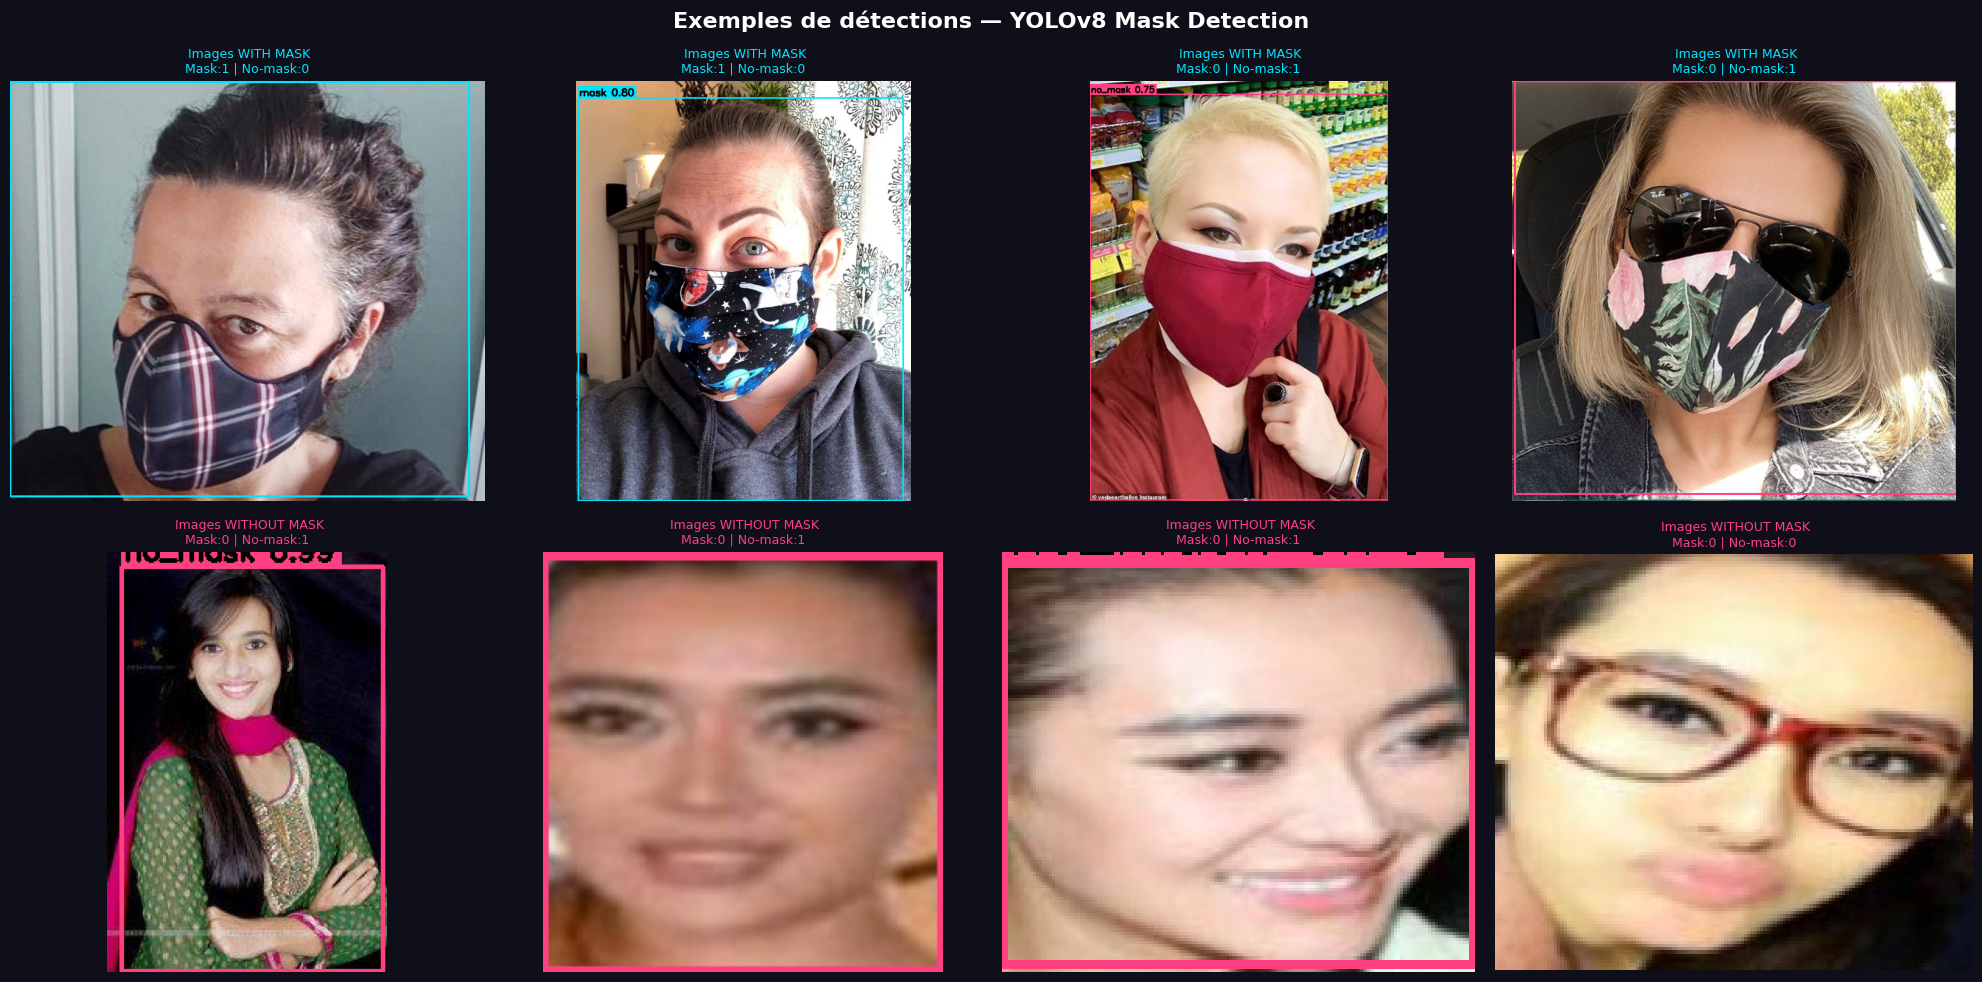

 Grille visuelle sauvegardée


In [24]:
# ─── Grille d'exemples visuels finaux ───────────────────────────
exts = ('.jpg', '.jpeg', '.png', '.bmp')

imgs_m = [os.path.join(DS2_WITH, f) for f in os.listdir(DS2_WITH)
          if f.lower().endswith(exts)][:4]
imgs_n = [os.path.join(DS2_WITHOUT, f) for f in os.listdir(DS2_WITHOUT)
          if f.lower().endswith(exts)][:4]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.patch.set_facecolor('#0f0f1a')
fig.suptitle('Exemples de détections — YOLOv8 Mask Detection',
             color='white', fontsize=16, fontweight='bold')

for row_idx, (imgs, row_label) in enumerate([(imgs_m, ' Images WITH MASK'), (imgs_n, ' Images WITHOUT MASK')]):
    for col_idx, img_path in enumerate(imgs):
        ax = axes[row_idx][col_idx]
        annotated, dets = detect_and_classify(img_path)
        if annotated is not None:
            ax.imshow(annotated)
        n_m = sum(1 for d in dets if d['label']=='mask')
        n_nm = sum(1 for d in dets if d['label']=='no_mask')
        ax.set_title(f'{row_label}\nMask:{n_m} | No-mask:{n_nm}',
                     color=COLORS['mask'] if row_idx==0 else COLORS['no_mask'], fontsize=9)
        ax.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'exemples_visuels_finaux.png', dpi=120, bbox_inches='tight')
plt.show()
print(' Grille visuelle sauvegardée')

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 10 — Bilan final et fichiers générés
</u>
</h1>
</div>
Cette dernière section affiche la liste de tous les fichiers produits par le notebook, avec leur taille, ainsi qu'un résumé complet du projet.


In [25]:
print('╔══════════════════════════════════════════════════════╗')
print('║          FICHIERS GÉNÉRÉS DANS /resultats/           ║')
print('╠══════════════════════════════════════════════════════╣')

for root, dirs, files in os.walk(OUTPUT_DIR):
    for f in sorted(files):
        full = os.path.join(root, f)
        size = os.path.getsize(full) / 1024
        rel  = os.path.relpath(full, OUTPUT_DIR)
        print(f'║   {rel:<40} {size:6.1f} KB  ║')

print('╚══════════════════════════════════════════════════════╝')
print()
print(' Projet Mask Detection — Approche 1 (YOLOv8) TERMINÉ')
print('\n Résumé pour le professeur :')
print(f'   Dataset 1 : {count_images(DS1_MASKED)+count_images(DS1_NONMASKED)} images (crops)')
print(f'   Dataset 2 : {count_images(DS2_WITH)+count_images(DS2_WITHOUT)} images (complètes)')
print(f'   Modèle    : YOLOv8n (pré-entraîné)')
print(f'   Tests     : Images individuelles | Dataset complet | Webcam | Vidéo')
print(f'   Métriques : Accuracy / Precision / Recall / F1 Score / Confusion Matrix')

╔══════════════════════════════════════════════════════╗
║          FICHIERS GÉNÉRÉS DANS /resultats/           ║
╠══════════════════════════════════════════════════════╣
║   confusion_matrix_ds2.png                   34.8 KB  ║
║   distribution_dataset.png                   70.3 KB  ║
║   exemples_visuels_finaux.png              2025.8 KB  ║
║   metriques_comparatif.png                   61.8 KB  ║
║   tableau_metriques.png                      64.7 KB  ║
║   test1_images_individuelles.png           1746.4 KB  ║
║   video_annotee.mp4                        3603.7 KB  ║
║   video_stats.png                            49.7 KB  ║
║   webcam_capture_01.png                     376.5 KB  ║
║   images_annotees\test1_00.png              405.7 KB  ║
║   images_annotees\test1_01.png              775.3 KB  ║
║   images_annotees\test1_02.png              705.8 KB  ║
║   images_annotees\test1_03.png              658.8 KB  ║
║   images_annotees\test1_04.png              585.8 KB  ║
║   images_annote